<a href="https://colab.research.google.com/github/iqbaal24/ML2026/blob/main/week11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS11 - Klasifikasi 2 (SVM)
**Praktikum Pembelajaran Mesin**

Notebook ini berisi seluruh isi jobsheet JS11, yaitu Praktikum 1 sampai Praktikum 5, lalu Tugas Praktikum 1 dan 2.

**Persiapan file sebelum menjalankan (upload ke Colab / taruh satu folder dengan notebook):**
- `voice.csv` (untuk Tugas 1)
- `images.zip` (untuk Praktikum 5 dan Tugas 2). Hasil ekstrak harus berisi folder `images/training/day`, `images/training/night`, `images/test/day`, `images/test/night`.

In [1]:
# Import library yang dipakai di seluruh notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns
import cv2
from pathlib import Path
from scipy import stats

from sklearn.svm import SVC
from sklearn.datasets import make_blobs, make_circles
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import warnings
warnings.filterwarnings('ignore')

---
# Praktikum 1 - Klasifikasi SVM dengan Data Dummy Linier

## Langkah 2 - Membuat Data Dummy

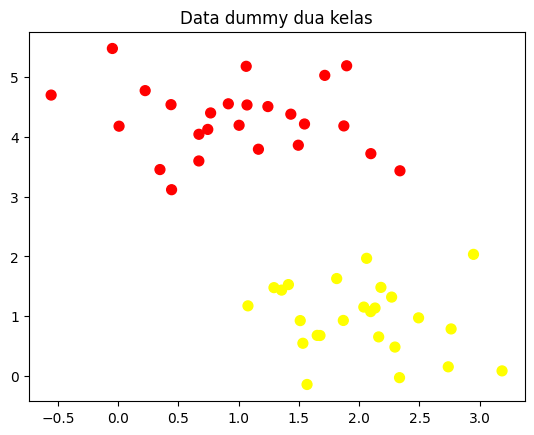

In [2]:
X, y = make_blobs(n_samples=50, centers=2,
                  random_state=0, cluster_std=0.60)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.title('Data dummy dua kelas')
plt.show()

## Langkah 3 - Ilustrasi Garis Pemisah

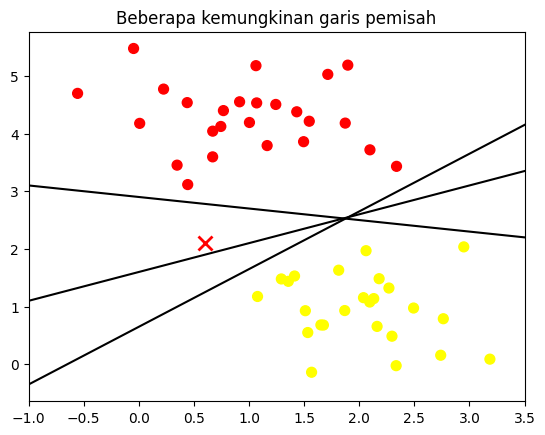

In [3]:
xfit = np.linspace(-1, 3.5)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.plot([0.6], [2.1], 'x', color='red', markeredgewidth=2, markersize=10)

for m, b in [(1, 0.65), (0.5, 1.6), (-0.2, 2.9)]:
    plt.plot(xfit, m * xfit + b, '-k')

plt.xlim(-1, 3.5)
plt.title('Beberapa kemungkinan garis pemisah')
plt.show()

## Langkah 4 - Ilustrasi Margin

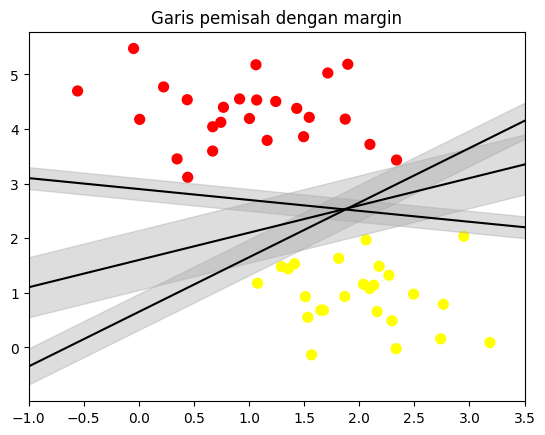

In [4]:
xfit = np.linspace(-1, 3.5)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
    yfit = m * xfit + b
    plt.plot(xfit, yfit, '-k')
    plt.fill_between(xfit, yfit - d, yfit + d, edgecolor='none',
                     color='#AAAAAA', alpha=0.4)

plt.xlim(-1, 3.5)
plt.title('Garis pemisah dengan margin')
plt.show()

## Langkah 5 - Fitting Model

In [5]:
model = SVC(kernel='linear', C=1E10)
model.fit(X, y)

SVC(C=10000000000.0, kernel='linear')

In [6]:
# fungsi untuk menampilkan hasil fitting (dipakai juga di Praktikum 2 dan 3)
def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

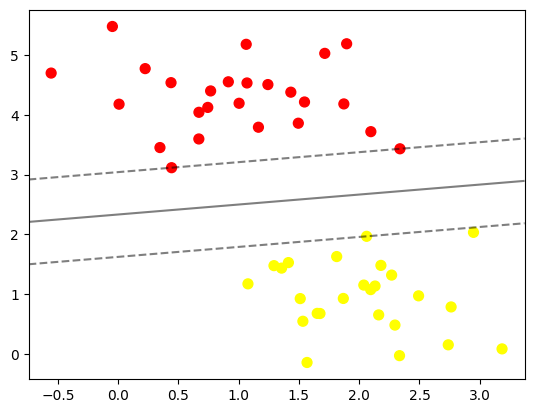

In [7]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(model)
plt.show()

In [8]:
model.support_vectors_

array([[0.44359863, 3.11530945],
       [2.33812285, 3.43116792],
       [2.06156753, 1.96918596]])

Titik data yang menyentuh margin disebut *support vector*. Hanya titik-titik ini yang menentukan posisi garis pemisah. Data lain yang jauh dari margin tidak berpengaruh. Bagian di bawah membuktikannya dengan membandingkan model yang dilatih dengan 60 dan 120 data.

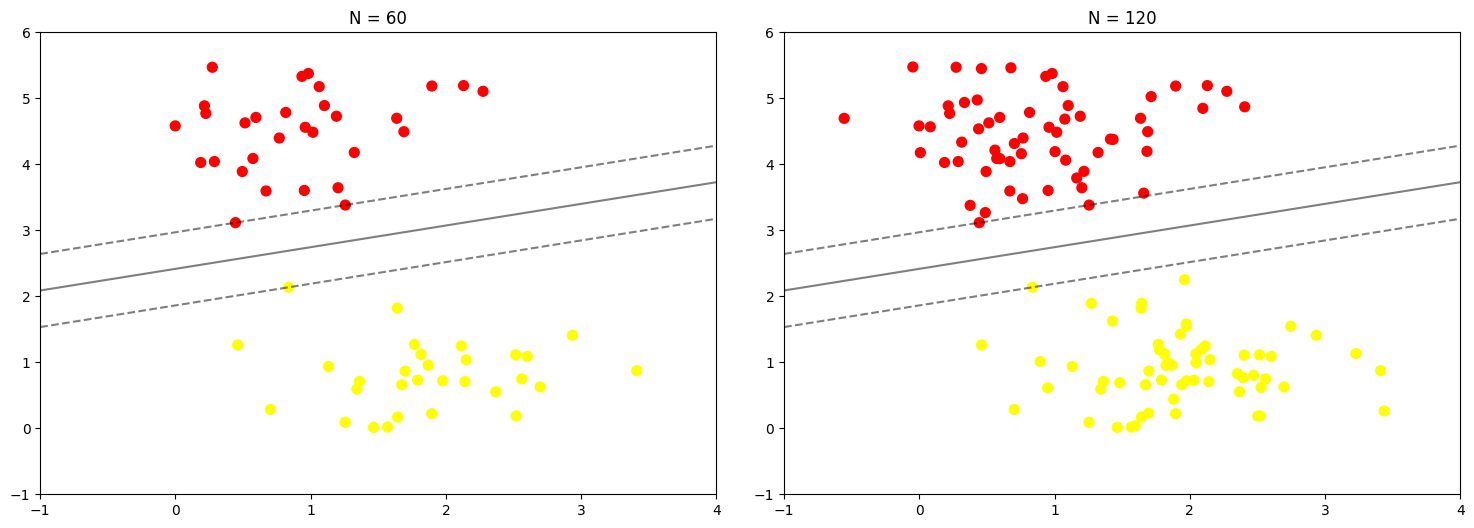

In [9]:
def plot_svm(N=10, ax=None):
    X, y = make_blobs(n_samples=200, centers=2,
                      random_state=0, cluster_std=0.60)
    X = X[:N]
    y = y[:N]
    model = SVC(kernel='linear', C=1E10)
    model.fit(X, y)

    ax = ax or plt.gca()
    ax.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    ax.set_xlim(-1, 4)
    ax.set_ylim(-1, 6)
    plot_svc_decision_function(model, ax)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
for axi, N in zip(ax, [60, 120]):
    plot_svm(N, axi)
    axi.set_title('N = {0}'.format(N))
plt.show()

Versi interaktif memakai `ipywidgets`. Jika tidak berjalan di Colab, jalankan `!pip install ipywidgets` terlebih dahulu. Sebagai gantinya, sel di bawah ini menampilkan N = 10 dan N = 200 secara berdampingan tanpa widget.

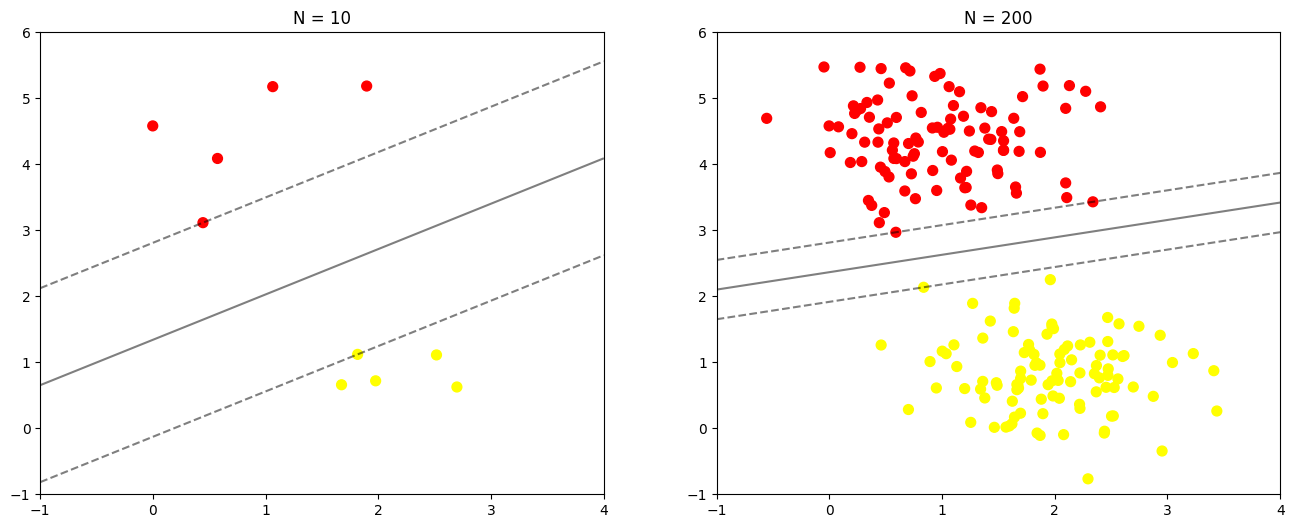

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
for axi, N in zip(ax, [10, 200]):
    plot_svm(N, axi)
    axi.set_title('N = {0}'.format(N))
plt.show()

---
# Praktikum 2 - Klasifikasi SVM dengan Data Dummy Non-Linier

## Langkah 1c - Data Dummy Non-Linier

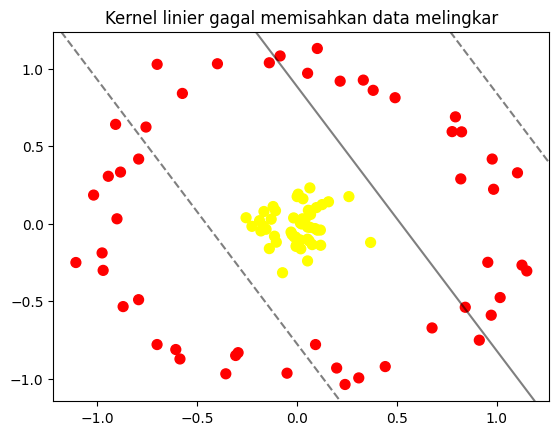

In [11]:
X, y = make_circles(100, factor=.1, noise=.1)

clf = SVC(kernel='linear').fit(X, y)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf, plot_support=False);
plt.title('Kernel linier gagal memisahkan data melingkar')
plt.show()

Garis linier tidak bisa memisahkan data. Karena itu dipakai proyeksi radial, lalu divisualisasikan dalam 3D.

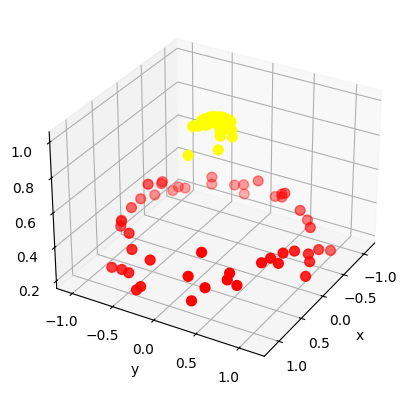

In [12]:
from mpl_toolkits import mplot3d

r = np.exp(-(X ** 2).sum(1))

def plot_3D(elev=30, azim=30, X=X, y=y):
    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('r')

plot_3D(elev=30, azim=30)
plt.show()

## Langkah 2 - Fitting Model dengan Kernel RBF

In [13]:
clf = SVC(kernel='rbf', C=1E6)
clf.fit(X, y)

SVC(C=1000000.0)

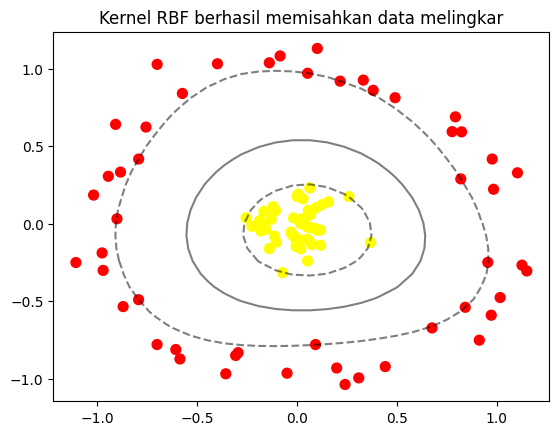

In [14]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf)
plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
            s=300, lw=1, facecolors='none')
plt.title('Kernel RBF berhasil memisahkan data melingkar')
plt.show()

---
# Praktikum 3 - SVM Data Overlapping

## Langkah 2 - Buat Data Dummy

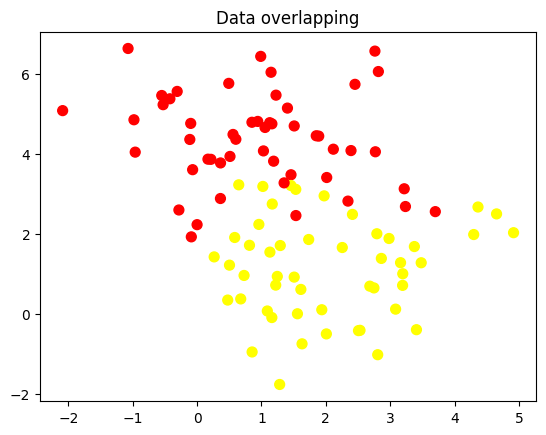

In [15]:
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=1.2)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.title('Data overlapping')
plt.show()

## Langkah 3 - Analisis Dampak Tuning (parameter C)

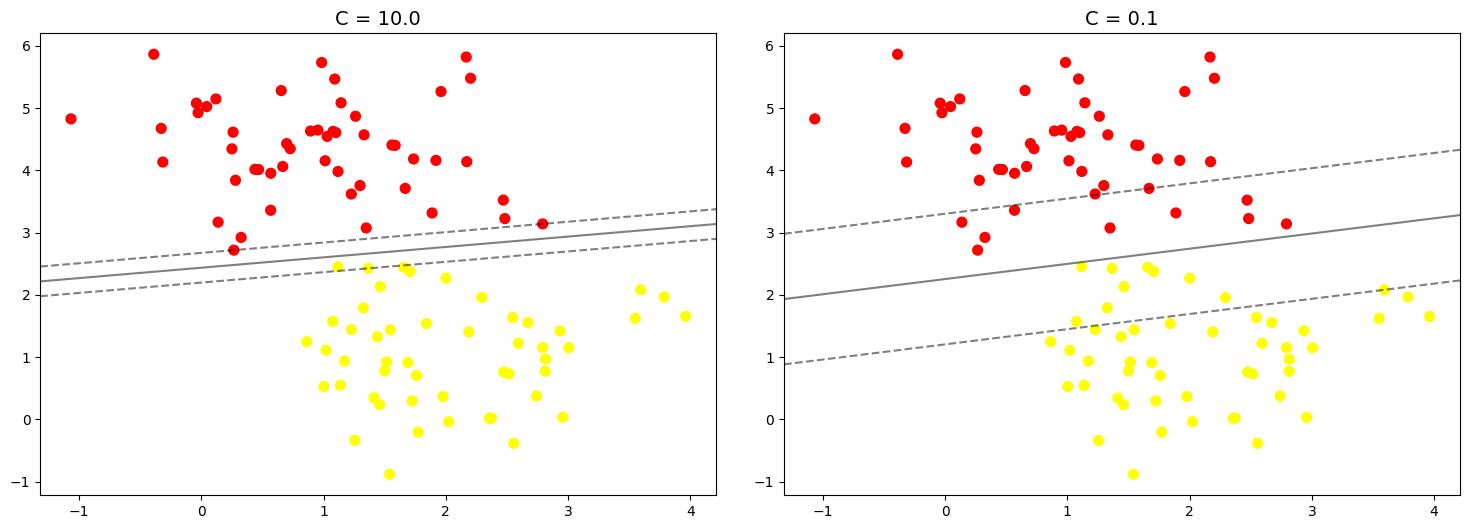

In [16]:
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=0.8)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

for axi, C in zip(ax, [10.0, 0.1]):
    model = SVC(kernel='linear', C=C).fit(X, y)
    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    plot_svc_decision_function(model, axi)
    axi.scatter(model.support_vectors_[:, 0],
                model.support_vectors_[:, 1],
                s=300, lw=1, facecolors='none');
    axi.set_title('C = {0:.1f}'.format(C), size=14)
plt.show()

Nilai C yang besar membuat margin keras (sedikit toleransi kesalahan), sedangkan C kecil membuat margin lebih longgar dan menyerap lebih banyak titik. Nilai C terbaik tergantung dataset dan dicari dengan cross-validation.

---
# Praktikum 4 - Klasifikasi Citra Wajah
Dataset diunduh otomatis lewat scikit-learn, jadi butuh internet dan waktu unduh yang agak lama.

## Langkah 0 - Unduh Dataset

In [17]:
from sklearn.datasets import fetch_lfw_people
faces = fetch_lfw_people(min_faces_per_person=60)
print(faces.target_names)
print(len(faces.target_names))
print(faces.images.shape)

['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
8
(1348, 62, 47)


## Langkah 1 - Inspeksi Citra Wajah

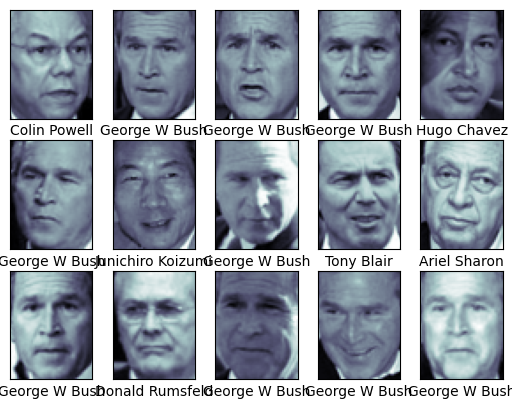

In [18]:
fig, ax = plt.subplots(3, 5)
for i, axi in enumerate(ax.flat):
    axi.imshow(faces.images[i], cmap='bone')
    axi.set(xticks=[], yticks=[],
            xlabel=faces.target_names[faces.target[i]])
plt.show()

## Langkah 2 - Pra Pengolahan Data (PCA + SVM)

In [19]:
from sklearn.decomposition import PCA as RandomizedPCA

pca = RandomizedPCA(n_components=150, whiten=True, random_state=42)
svc = SVC(kernel='rbf', class_weight='balanced')
model = make_pipeline(pca, svc)

## Langkah 3 - Split Data

In [20]:
Xtrain, Xtest, ytrain, ytest = train_test_split(faces.data, faces.target,
                                                random_state=42)

## Langkah 4 - Pembuatan Model + Tuning (GridSearchCV)

In [21]:
param_grid = {'svc__C': [1, 5, 10, 50],
              'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]}
grid = GridSearchCV(model, param_grid)

%time grid.fit(Xtrain, ytrain)
print(grid.best_params_)
print(grid.best_score_)

CPU times: user 2min 11s, sys: 216 ms, total: 2min 11s
Wall time: 1min 22s
{'svc__C': 5, 'svc__gamma': 0.001}
0.828893332683022


In [22]:
model = grid.best_estimator_
yfit = model.predict(Xtest)

## Langkah 5 - Cek Hasil Prediksi

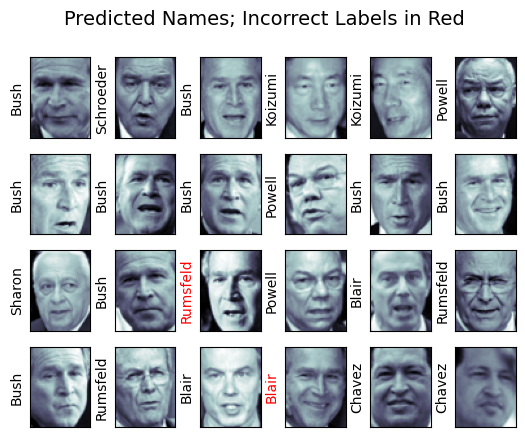

In [23]:
fig, ax = plt.subplots(4, 6)
for i, axi in enumerate(ax.flat):
    axi.imshow(Xtest[i].reshape(62, 47), cmap='bone')
    axi.set(xticks=[], yticks=[])
    axi.set_ylabel(faces.target_names[yfit[i]].split()[-1],
                   color='black' if yfit[i] == ytest[i] else 'red')
fig.suptitle('Predicted Names; Incorrect Labels in Red', size=14)
plt.show()

## Langkah 6 - Cek Performansi

In [24]:
print(classification_report(ytest, yfit,
                            target_names=faces.target_names))

                   precision    recall  f1-score   support

     Ariel Sharon       0.65      0.87      0.74        15
     Colin Powell       0.83      0.88      0.86        68
  Donald Rumsfeld       0.70      0.84      0.76        31
    George W Bush       0.97      0.80      0.88       126
Gerhard Schroeder       0.76      0.83      0.79        23
      Hugo Chavez       0.93      0.70      0.80        20
Junichiro Koizumi       0.86      1.00      0.92        12
       Tony Blair       0.82      0.98      0.89        42

         accuracy                           0.85       337
        macro avg       0.82      0.86      0.83       337
     weighted avg       0.86      0.85      0.85       337



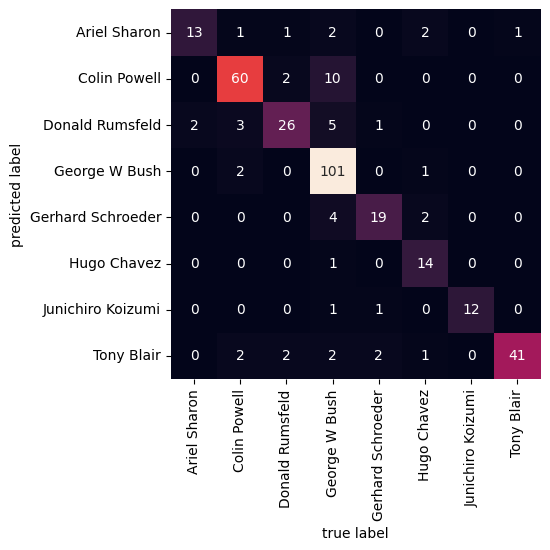

In [25]:
mat = confusion_matrix(ytest, yfit)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=faces.target_names,
            yticklabels=faces.target_names)
plt.xlabel('true label')
plt.ylabel('predicted label')
plt.show()

---
# Praktikum 5 - Klasifikasi Citra Siang dan Malam
Pastikan `images.zip` sudah di-upload. Sel berikut mengekstraknya (dilewati jika folder `images` sudah ada).

In [27]:
from google.colab import files
uploaded = files.upload()

Saving images.zip to images.zip


In [28]:
import zipfile, os

if not os.path.isdir('images'):
    with zipfile.ZipFile('images.zip', 'r') as z:
        z.extractall('.')

# kalau hasil ekstrak berada di dalam folder lain, ubah dua baris ini
train_dir = "images/training/"
test_dir = "images/test/"
print(os.listdir(train_dir), os.listdir(test_dir))

['day', 'night'] ['day', 'night']


## Langkah 1 - Load Data dan Visualisasikan

In [29]:
def load_dataset(img_dir):
    p = Path(img_dir)
    dirs = p.glob('*')

    img_list = []

    for dir in dirs:
        label = dir.name          # nama folder = label (day / night)
        for file in dir.glob('*.jpg'):
            img = mpimg.imread(file)

            if img is not None:
                img_list.append((img, label))

    return img_list

train_img = load_dataset(train_dir)
print('Jumlah data training:', len(train_img))
train_img[0][1]

Jumlah data training: 240


'day'

In [30]:
pick_random = np.random.randint(0, len(train_img))
print(f'Image {pick_random}')
print(train_img[pick_random][0].shape)

Image 171
(591, 800, 3)


Shape	: (469, 640, 3)
Label	: night


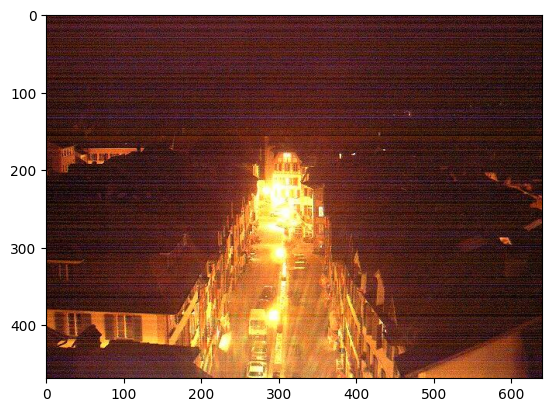

In [31]:
def random_img_viz(img_list):
    rand_num = np.random.randint(0, len(img_list))

    img = img_list[rand_num][0]
    label = img_list[rand_num][1]

    plt.imshow(img)
    print(f'Shape\t: {img.shape}')
    print(f'Label\t: {label}')

random_img_viz(train_img)

## Langkah 3 - Pra Pengolahan Data

In [32]:
def standarized_input(image):
    # resize ke w: 1100, h: 600
    std_img = cv2.resize(image, (1100, 600))
    return std_img

def label_encoder(label):
    # day = 1, night = 0
    num_val = 0
    if label == 'day':
        num_val = 1
    return num_val

def preprocess(img_list):
    std_img_list = []

    for item in img_list:
        image = item[0]
        label = item[1]

        std_img = standarized_input(image)
        img_label = label_encoder(label)

        std_img_list.append((std_img, img_label))

    return std_img_list

train_std_img_list = preprocess(train_img)

pick_random = np.random.randint(0, len(train_std_img_list))
print(f'Image {pick_random}')
print(train_std_img_list[pick_random][0].shape)

Image 128
(600, 1100, 3)


Shape	: (600, 1100, 3)
Label	: 0


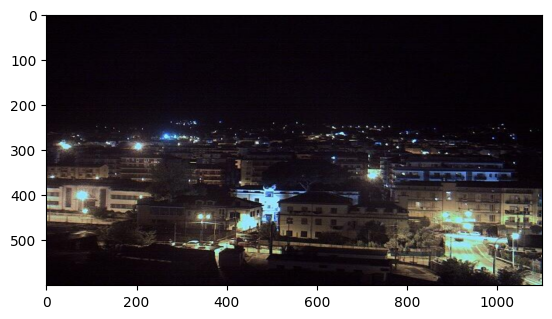

In [33]:
random_img_viz(train_std_img_list)

## Langkah 4 - Ekstraksi Fitur (rata-rata kecerahan, HSV)

Image 34
Avg Brighness: 139.7860


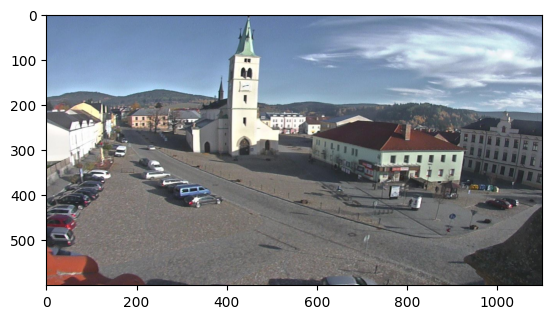

In [34]:
def avg_brightness(image):
    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    sum_brightness = np.sum(img_hsv[:, :, 2])   # channel V
    area = image.shape[0] * image.shape[1]
    avg = sum_brightness / area
    return avg

rand_img = np.random.randint(0, len(train_std_img_list))
feature_img = train_std_img_list[rand_img][0]
avg_img = avg_brightness(feature_img)

print(f'Image {rand_img}')
print(f'Avg Brighness: {avg_img:.4f}')
plt.imshow(feature_img)
plt.show()

## Langkah 5 - Klasifikasi dengan Metode Threshold

Image 128
Actual label: 0
Predicted label: 0


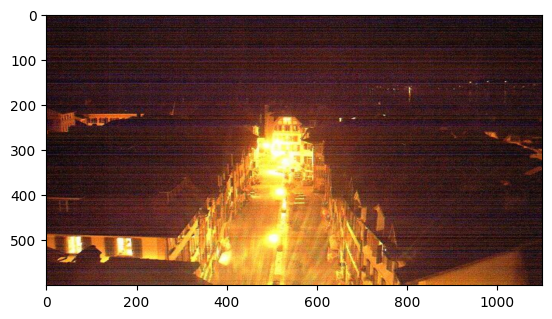

In [35]:
def predict_label(img, threshold):
    avg = avg_brightness(img)
    pred = 0
    if avg > threshold:
        pred = 1
    return pred

rand_img = np.random.randint(0, len(train_std_img_list))
pred = predict_label(train_std_img_list[rand_img][0], threshold=120)

print(f'Image {rand_img}')
print(f'Actual label: {train_std_img_list[rand_img][1]}')
print(f'Predicted label: {pred}')
plt.imshow(train_std_img_list[rand_img][0])
plt.show()

## Langkah 6 - Evaluasi Manual

In [36]:
def evaluate(img_list, threshold):
    miss_labels = []

    for file in img_list:
        img = file[0]
        label = file[1]

        pred_label = predict_label(img, threshold)

        if pred_label != label:
            miss_labels.append((img, pred_label, label))

    total_img = len(img_list)
    corr_pred = total_img - len(miss_labels)
    accuracy = corr_pred / total_img

    print(f'Accuracy: {accuracy:.4f}')

# data training
evaluate(train_std_img_list, threshold=120)

Accuracy: 0.8417


In [37]:
# data testing (harus diperlakukan sama seperti data training)
test_img = load_dataset(test_dir)
test_std_img_list = preprocess(test_img)
evaluate(test_std_img_list, threshold=120)

Accuracy: 0.8688


## Klasifikasi dengan SVM - Langkah 4 Alternatif (Feature Vectors)

In [38]:
def extract_avg_bright_feature(img_list):
    avg_list = []
    labels = []

    for img in img_list:
        img_avg = avg_brightness(img[0])
        img_label = img[1]

        avg_list.append(img_avg)
        labels.append(img_label)

    data = np.column_stack((avg_list, labels))
    df = pd.DataFrame(data, columns=['AVG_BRIGHT', 'LABELS'])
    return df

train_avg_img = extract_avg_bright_feature(train_std_img_list)
print(f'Shape: {train_avg_img.shape}')
display(train_avg_img.head())

test_avg_img = extract_avg_bright_feature(test_std_img_list)
print(f'Shape: {test_avg_img.shape}')
display(test_avg_img.head())

Shape: (240, 2)


,AVG_BRIGHT,LABELS
0,111.255202,1.0
1,132.133823,1.0
2,123.617420,1.0
3,129.322923,1.0
4,158.018809,1.0


Shape: (160, 2)


,AVG_BRIGHT,LABELS
0,149.179342,1.0
1,159.288420,1.0
2,151.462197,1.0
3,141.376232,1.0
4,98.868853,1.0


## Langkah 5 dan 6 - Model SVM dan Evaluasi

In [39]:
X_train = train_avg_img.iloc[:, 0].values.reshape(-1, 1)
y_train = train_avg_img.iloc[:, 1]
X_test = test_avg_img.iloc[:, 0].values.reshape(-1, 1)
y_test = test_avg_img.iloc[:, 1]

model = SVC()
model.fit(X_train, y_train)

y_train_pred = model.predict(X_train)
acc_train = accuracy_score(y_train, y_train_pred)

y_test_pred = model.predict(X_test)
acc_test = accuracy_score(y_test, y_test_pred)

print(f'Accuracy on train: {acc_train}')
print(f'Accuracy on test: {acc_test}')

Accuracy on train: 0.8583333333333333
Accuracy on test: 0.9


---
# Tugas Praktikum 1 - SVM pada `voice.csv`

Ketentuan: split 70:30 dan 80:20, masing-masing dengan kernel linier, polynomial, dan RBF. Hasilnya ditabulasikan berdasarkan akurasi.

In [41]:
from google.colab import files
uploaded = files.upload()

Saving voice.csv to voice.csv


In [42]:
df_voice = pd.read_csv('voice.csv')
print(df_voice.shape)
display(df_voice.head())
print(df_voice['label'].value_counts())
print('Missing value:', df_voice.isnull().sum().sum())

(3168, 21)


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


label
male      1584
female    1584
Name: count, dtype: int64
Missing value: 0


Kolom `label` (male/female) diubah ke angka. Fitur dinormalisasi dengan `StandardScaler`, karena SVM sensitif terhadap skala fitur. Scaler hanya di-fit pada data training agar tidak terjadi kebocoran data.

In [43]:
X_v = df_voice.drop(columns=['label'])
y_v = LabelEncoder().fit_transform(df_voice['label'])

splits = {'70:30': 0.30, '80:20': 0.20}
kernels = ['linear', 'poly', 'rbf']

hasil = []
for nama_split, test_size in splits.items():
    Xtr, Xte, ytr, yte = train_test_split(
        X_v, y_v, test_size=test_size, random_state=42, stratify=y_v)

    scaler = StandardScaler().fit(Xtr)
    Xtr_s = scaler.transform(Xtr)
    Xte_s = scaler.transform(Xte)

    for k in kernels:
        svm = SVC(kernel=k, random_state=42)
        svm.fit(Xtr_s, ytr)
        acc = accuracy_score(yte, svm.predict(Xte_s))
        hasil.append({'Split': nama_split, 'Kernel': k, 'Akurasi': acc})
        print(f'Split {nama_split} | kernel {k:6s} | akurasi = {acc:.4f}')

df_hasil = pd.DataFrame(hasil)

Split 70:30 | kernel linear | akurasi = 0.9790
Split 70:30 | kernel poly   | akurasi = 0.9600
Split 70:30 | kernel rbf    | akurasi = 0.9832
Split 80:20 | kernel linear | akurasi = 0.9748
Split 80:20 | kernel poly   | akurasi = 0.9558
Split 80:20 | kernel rbf    | akurasi = 0.9826


### Tabulasi performa (akurasi)

In [44]:
tabel = df_hasil.pivot(index='Kernel', columns='Split', values='Akurasi')
tabel = tabel.loc[['linear', 'poly', 'rbf']]
display(tabel.style.format('{:.4f}').background_gradient(cmap='Blues', axis=None))

Split,70:30,80:20
Kernel,,
linear,0.9790,0.9748
poly,0.9600,0.9558
rbf,0.9832,0.9826


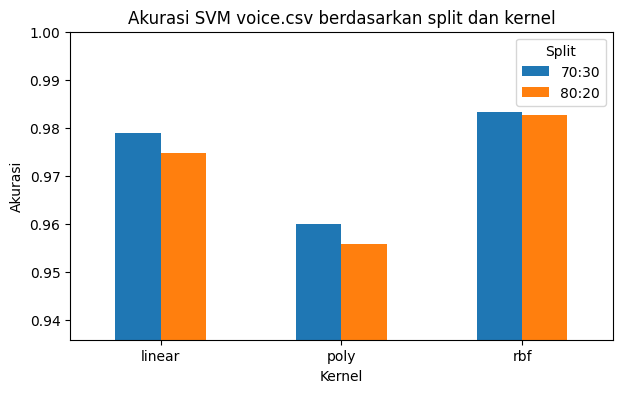

Akurasi tertinggi: 0.9832 (split 70:30, kernel rbf)


In [45]:
tabel.plot(kind='bar', figsize=(7, 4))
plt.ylabel('Akurasi')
plt.title('Akurasi SVM voice.csv berdasarkan split dan kernel')
plt.ylim(tabel.values.min() - 0.02, 1.0)
plt.xticks(rotation=0)
plt.legend(title='Split')
plt.show()

best = df_hasil.loc[df_hasil['Akurasi'].idxmax()]
print(f"Akurasi tertinggi: {best['Akurasi']:.4f} (split {best['Split']}, kernel {best['Kernel']})")

**Analisis singkat:** isi kesimpulan sendiri setelah melihat hasil di atas, misalnya kernel mana yang paling baik, apakah perubahan rasio split berpengaruh besar, dan kenapa kernel non-linier (RBF/polynomial) bisa lebih unggul dari linier pada data suara ini.

---
# Tugas Praktikum 2 - Klasifikasi Siang dan Malam dengan SVM RBF (Fitur Histogram)

Data memakai dataset Praktikum 5. Fitur yang dipakai adalah **histogram kecerahan** (channel V pada HSV) dengan 32 bin yang dinormalisasi. Gambar training dan test digabung, lalu dibagi ulang dengan rasio **80:20**.

In [46]:
N_BINS = 32

def hist_feature(image, bins=N_BINS):
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    h = cv2.calcHist([hsv], [2], None, [bins], [0, 256]).flatten()
    h = h / h.sum()          # normalisasi supaya tidak bergantung ukuran gambar
    return h

# gabungkan semua gambar (sudah di-resize & di-encode di Praktikum 5)
all_std = train_std_img_list + test_std_img_list

X_hist = np.array([hist_feature(img) for img, _ in all_std])
y_hist = np.array([lbl for _, lbl in all_std])
print('Shape fitur:', X_hist.shape, '| shape label:', y_hist.shape)
print('Jumlah per kelas (0=night, 1=day):', np.bincount(y_hist))

Shape fitur: (400, 32) | shape label: (400,)
Jumlah per kelas (0=night, 1=day): [200 200]


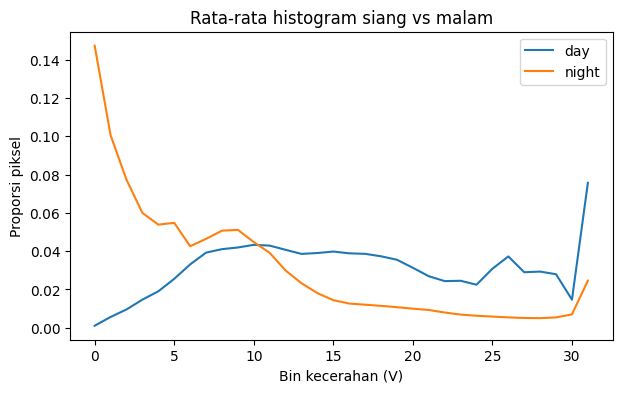

In [47]:
# contoh rata-rata histogram tiap kelas
plt.figure(figsize=(7, 4))
plt.plot(X_hist[y_hist == 1].mean(axis=0), label='day')
plt.plot(X_hist[y_hist == 0].mean(axis=0), label='night')
plt.xlabel('Bin kecerahan (V)')
plt.ylabel('Proporsi piksel')
plt.title('Rata-rata histogram siang vs malam')
plt.legend()
plt.show()

In [48]:
Xtr, Xte, ytr, yte = train_test_split(
    X_hist, y_hist, test_size=0.20, random_state=42, stratify=y_hist)

# baseline: SVM RBF parameter default
base = make_pipeline(StandardScaler(), SVC(kernel='rbf'))
base.fit(Xtr, ytr)
acc_base = accuracy_score(yte, base.predict(Xte))
print(f'Akurasi baseline (C=1, gamma=scale): {acc_base:.4f}')

Akurasi baseline (C=1, gamma=scale): 0.9875


### Eksperimen hyperparameter tuning (C dan gamma)

In [49]:
param_grid = {
    'svc__C': [0.1, 1, 10, 100, 1000],
    'svc__gamma': ['scale', 0.0001, 0.001, 0.01, 0.1, 1],
}
pipe = make_pipeline(StandardScaler(), SVC(kernel='rbf'))
grid = GridSearchCV(pipe, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid.fit(Xtr, ytr)

print('Parameter terbaik :', grid.best_params_)
print(f'Akurasi CV terbaik : {grid.best_score_:.4f}')

best_model = grid.best_estimator_
y_pred = best_model.predict(Xte)
acc_tuned = accuracy_score(yte, y_pred)
print(f'Akurasi test setelah tuning: {acc_tuned:.4f}')

Parameter terbaik : {'svc__C': 10, 'svc__gamma': 0.1}
Akurasi CV terbaik : 0.9875
Akurasi test setelah tuning: 1.0000


In [50]:
# tabel hasil semua kombinasi (akurasi CV)
res = pd.DataFrame(grid.cv_results_)
tbl = res.pivot_table(index='param_svc__C', columns='param_svc__gamma',
                      values='mean_test_score')
display(tbl.style.format('{:.4f}').background_gradient(cmap='Blues', axis=None))

param_svc__gamma,0.000100,0.001000,0.010000,0.100000,1,scale
param_svc__C,,,,,,
0.100000,0.8625,0.8688,0.8844,0.9375,0.6781,0.9250
1.000000,0.8625,0.8969,0.9469,0.9844,0.9156,0.9750
10.000000,0.8906,0.9250,0.9781,0.9875,0.9219,0.9844
100.000000,0.9250,0.9844,0.9781,0.9875,0.9219,0.9875
1000.000000,0.9875,0.9844,0.9781,0.9875,0.9219,0.9875


              precision    recall  f1-score   support

       night       1.00      1.00      1.00        40
         day       1.00      1.00      1.00        40

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80



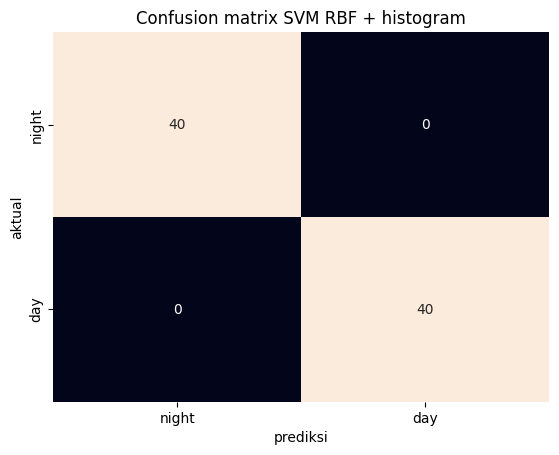

In [51]:
print(classification_report(yte, y_pred, target_names=['night', 'day']))

sns.heatmap(confusion_matrix(yte, y_pred), annot=True, fmt='d', cbar=False,
            xticklabels=['night', 'day'], yticklabels=['night', 'day'])
plt.xlabel('prediksi')
plt.ylabel('aktual')
plt.title('Confusion matrix SVM RBF + histogram')
plt.show()

### Catatan performa akurasi

In [52]:
ringkas = pd.DataFrame({
    'Model': ['SVM RBF default (C=1, gamma=scale)', f"SVM RBF tuning {grid.best_params_}"],
    'Akurasi test': [acc_base, acc_tuned],
})
display(ringkas.style.format({'Akurasi test': '{:.4f}'}))

,Model,Akurasi test
0,"SVM RBF default (C=1, gamma=scale)",0.9875
1,"SVM RBF tuning {'svc__C': 10, 'svc__gamma': 0.1}",1.0000


**Analisis singkat:** bandingkan akurasi baseline dengan hasil tuning, jelaskan pengaruh C dan gamma, dan bandingkan dengan akurasi memakai satu fitur rata-rata kecerahan di Praktikum 5.